# Statistical Inference & Modelling Poker Datasets

### Contents 

Chapter 0. Libraries, Modules & Setting Up \
Chapter 1. Luck Vs Skill \
Chapter 2. Profit Distribution \
Chapter 3. Overall Ratings (OVR) \

### Chapter 0. Libraries, Modules & Setting Up

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
from scipy.stats import norm
from matplotlib.colors import to_rgba

from config import player_colours
from more_styles import (BG, FG, MUTED, profit_gbp, profit_title_block, profit_footer,
                         title_block, footer, soften_axes, soften_legend)

plt.style.use("rose-pine")      # set once; applies to every figure below

def load_games(path="AllRecordedGames.csv") -> pd.DataFrame:
    df = pd.read_csv(path, usecols=["game_id", "player", "buy_in", "cash_out"])
    df["player"] = df["player"].str.strip()
    df["profit"] = (df["cash_out"] - df["buy_in"]).round(2)
    return df.sort_values("game_id", kind="stable").reset_index(drop=True)

games = load_games()
colour_of = lambda player: player_colours.get(player, "#888888")

### Chapter 1. Luck vs Skill

In this chapter we explore the relationship between luck and skill. By taking the null hypothesis that our poker is purely a game of luck, and no skill, we simulate how these games may have taken place if the results were completely random. 
$$
H_0:\ \text{every player}~i~\text{has the same chance of any given result in a game}
$$

From this point forwards we are assuming that a player only adds to their buy-in if they are in a weak position. Under $H_0$, adding to your buy-in is an outcome of play and we will assume each player has an equal chance of adding to their buy-in if they find themselves in a weak position.

Let there be $G\in\mathbb{N}$ games. The set $S$ is the set of all players in the database.

Game $g$ has a set of players $S_g$ where $n_g$ is the number of players in game $g$ such that $n_g = |S_g|$.

For some player $i\in S_g$, we have that their profit-loss (PL) in game $g$ is denoted by $x_{g,i}$ and defined by:

$$
x_{g,i}=\text{Buy-in}_{g,i} - \text{Cash-out}_{g,i}
$$

Player $i$'s total PL will be the sum of all their PL's across all games. Let $T_i$ be the sum of all player $i$'s results across all games they played. We write:

$$
T_i = \sum_{g:\, i \in S_g} x_{g,i}
$$
 
Where $g:\, i \in S_g$ is the condition that we sum all of $i$'s games in which they play and ignore the games they do not. A full view of the data at this point can be seen below. Mathemticallly, this can be read as 'sum over all $g$ such that player $i$ is in the set $S_g$'.

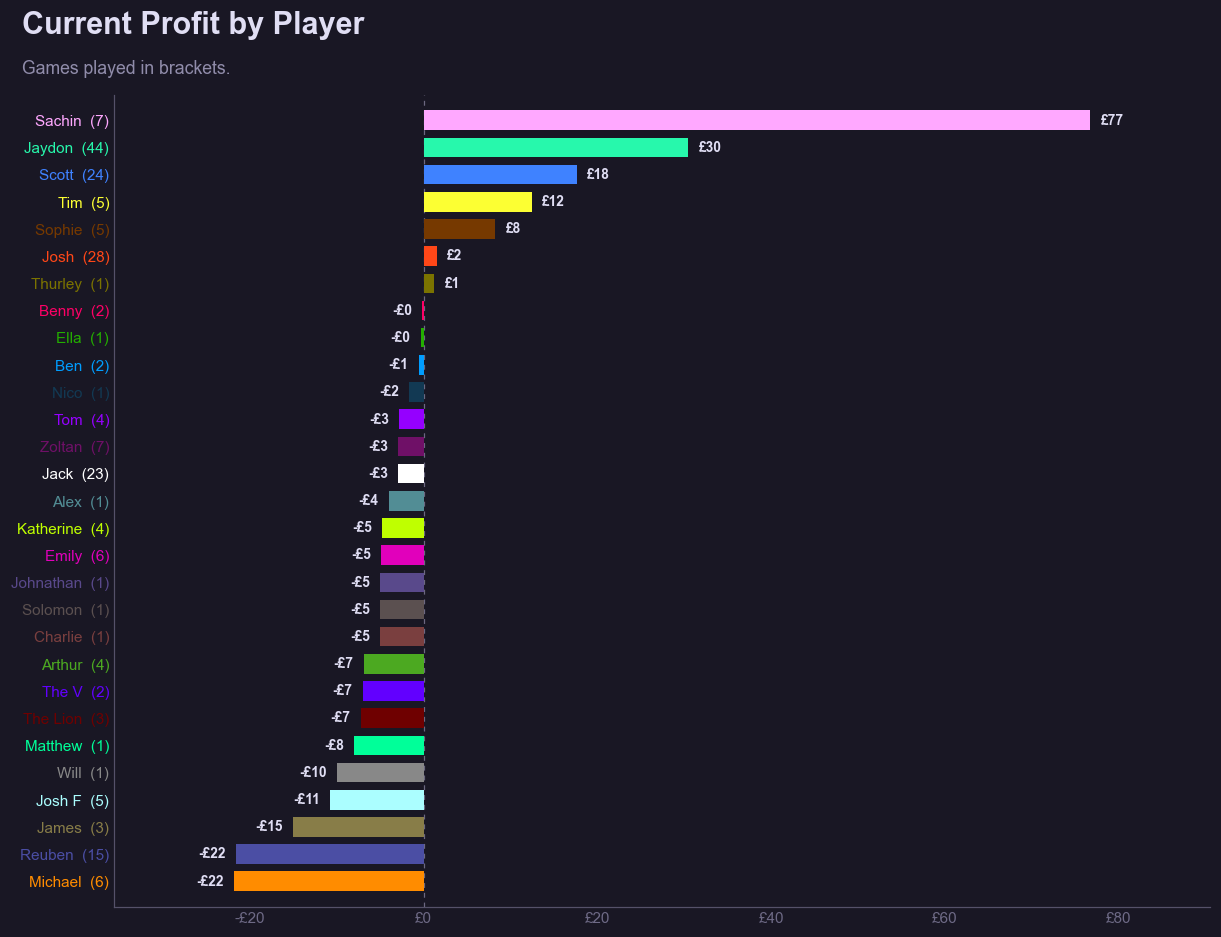

In [4]:
summary = (games.groupby("player")
                .agg(profit=("profit", "sum"), games=("game_id", "count"))
                .round(2)
                .sort_values("profit"))      

fig, ax = plt.subplots(figsize=(12, 9))

y       = np.arange(len(summary))
colours = [colour_of(p) for p in summary.index]
ax.barh(y, summary["profit"], color=colours, height=0.72, zorder=3)

# Value label at the end of every bar
span = summary["profit"].max() - summary["profit"].min()
for yi, val in zip(y, summary["profit"]):
    ax.text(val + (0.012 * span if val >= 0 else -0.012 * span), yi, profit_gbp(val),
            ha="left" if val >= 0 else "right", va="center",
            color=FG, fontsize=9, fontweight="bold")

# Break-even line
ax.axvline(0, color=MUTED, lw=0.8, ls=(0, (4, 4)), alpha=0.7, zorder=2)

# Axes
ax.set_yticks(y)
ax.set_yticklabels([f"{p}  ({g})" for p, g in zip(summary.index, summary["games"])], fontsize=10)
for lbl, col in zip(ax.get_yticklabels(), colours):
    lbl.set_color(col)
ax.xaxis.set_major_formatter(profit_gbp)
ax.margins(x=0.14, y=0.02)
ax.grid(False, axis="y")
ax.set_xlabel("")

fig.subplots_adjust(top=0.88, bottom=0.06, left=0.13, right=0.96)
profit_title_block(fig, ax, "Current Profit by Player", "Games played in brackets.")
profit_footer(fig)
plt.show()

#### Simulating a luck-only world

Under $H_0$, any way of handing out a game's results among its players is equally likely. So in each game we apply a random permutation of the results $\pi_g$ of the players:

$$x^*_{g,i} = x_{g,\pi_g(i)}$$

$\pi_g(i)$ just represents a shuffled expression of how $i$ initially performed in game $g$.

Each of the $n_g!$ permutations has probability $\frac{1}{n_g!}$, and the games are shuffled independently. One simulated version of the spreadsheet is one permutation chosen for every game, and its simulated totals are:

$$T^*_i = \sum_{g:\, i \in S_g} x^*_{g,i}$$

There are $\prod_{g} n_g!$ possible versions so we draw $N = 10{,}000$ at random, and each draw is one alternative history under $H_0$ based purely on luck. Note the following on how the shuffle works:
- Each game $g$ stays zero-sum
- The size of each game $n_g$ does not change
- The players in each game $g$ do not change.

Each simulation reshuffles who got which result within every game, so the results are the same but the winners are random. Repeating this 100,000 times shows how much spread luck alone produces.

In [6]:
N_SIMS = 100_000
SEED   = 42
KEEP   = 0

profit_obs  = games["profit"].to_numpy()
player_list = sorted(games["player"].unique())
n_players   = len(player_list)
player_idx  = games["player"].map({p: i for i, p in enumerate(player_list)}).to_numpy()
game_rows   = list(games.groupby("game_id").indices.values())              
eye         = np.eye(n_players)


def simulate(profit, player_idx, game_rows, n_sims, rng, keep=0):
    totals = np.zeros((n_sims, n_players))
    kept   = np.empty(len(profit))
    for rows in game_rows:
        order    = rng.random((n_sims, len(rows))).argsort(axis=1)  
        shuffled = profit[rows][order]                               
        totals  += shuffled @ eye[player_idx[rows]]                 
        kept[rows] = shuffled[keep]
    return np.round(totals, 2), kept


totals_obs = np.round(np.bincount(player_idx, weights=profit_obs, minlength=n_players), 2)
totals_sim, history = simulate(profit_obs, player_idx, game_rows, N_SIMS,
                               np.random.default_rng(SEED), keep=KEEP)                       

assert np.allclose(totals_sim.sum(axis=1), profit_obs.sum())
assert np.isclose(totals_obs.sum(), profit_obs.sum())
for rows in game_rows:
    assert np.allclose(np.sort(history[rows]), np.sort(profit_obs[rows]))

print(f"{N_SIMS:,} alternative histories | {games['game_id'].nunique()} games | "
      f"{n_players} players | {len(games)} player-games each")

100,000 alternative histories | 44 games | 29 players | 208 player-games each


Recall our null hypothesis. Under $H_0$, how spread out would the players' final profits be? Assuming that there is no skill involved. And is our real spread big enough to justify that there is some level of skill?

Recall our formula for player $i$'s total profit:

$$
T_i = \sum_{g:\, i \in S_g} x_{g,i}
$$

Our spread can be calculated by finding an estimation for the standard deviation, $\sigma_T$. 

Note, every game is zero-sum, so $\sum_i T_i = 0$ and recall that the total number of unique players in our database is $n = |S|$, where $S$ is the set of all players. This leads us to calculate a mean profit of $0$. See below. 

$$
\bar{T}=\frac{1}{n}\sum_{i=1}^{n} T_i=\frac{1}{n}(T_1+T_2+...+T_n)=0
$$

Now consider the formula for the standard deviation of all players profits, $\sigma_T$.

$$
\sigma_T = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(T_i - \bar{T}\right)^2}
$$

Which, with $\bar T=0$, becomes: 

$$
\sigma_T=\sqrt{\frac{1}{n}\sum_{1=n}^{n}T_i^{2}}
$$

A larger $\sigma_T$ means that the final/current results of each player are further apart, a large spread. The opposite holds true also.

Every alternative history $k = 1, \dots, N$ is a complete shuffled version of the original dataset, so it has its own totals $T^*_{k,i}$ and its own spread:

$$
\sigma^*_k = \sqrt{\frac{1}{n}\sum_{i=1}^{n} \left(T^*_{k,i}\right)^2}
$$

Taken together, the values $\sigma^*_1, \dots, \sigma^*_N$ show what spread luck alone produces, including how much it varies from one history to the next.

The graphs below show the spread of every single alternative history and how the spread of the real results compares. 

**Calculating the p-value**

We calculate a value which determines what proportion of total alternative histories produced a scenario spread, some $\sigma^*_k$, at least as extreme as our real spread, $\sigma_T$. We call this, the p-value. The p-value can be calculated as follows:

$$
p=\frac{\text{number of shuffled histories at least as spread out as reality}+1}{\text{number of shuffled histories}+1}
$$

We add one so our formula includes the real dataset and not just the shuffled histories. We can write this formula in a more formal fashion in the following suit:

$$
p = \frac{1 + \#\{k : \sigma^*_k \geq \sigma_T\}}{N + 1}
$$

Where $\#$ just means 'number of' and $\{k : \sigma^*_k \geq \sigma_T\}$ is the set of all shuffled histories $k$ such that its spread, $\sigma^*_k$ is greater than that of the spread of the real history. 

A small $p$ implies that luck alone rarely spreads players apart to this extreme, only this proportion of alternative histories produced under $H_0$ actually created an equivalent situation. 

A large $p$ implies that the real spread can easily be produced by luck.

Real spread:                £17.74
Luck-only spread (average): £13.33   (middle 90%: £9.45 to £18.14)
Histories at least as spread out as reality: 6,244 of 100,000
p = 0.062  (simulation error about ±0.001)


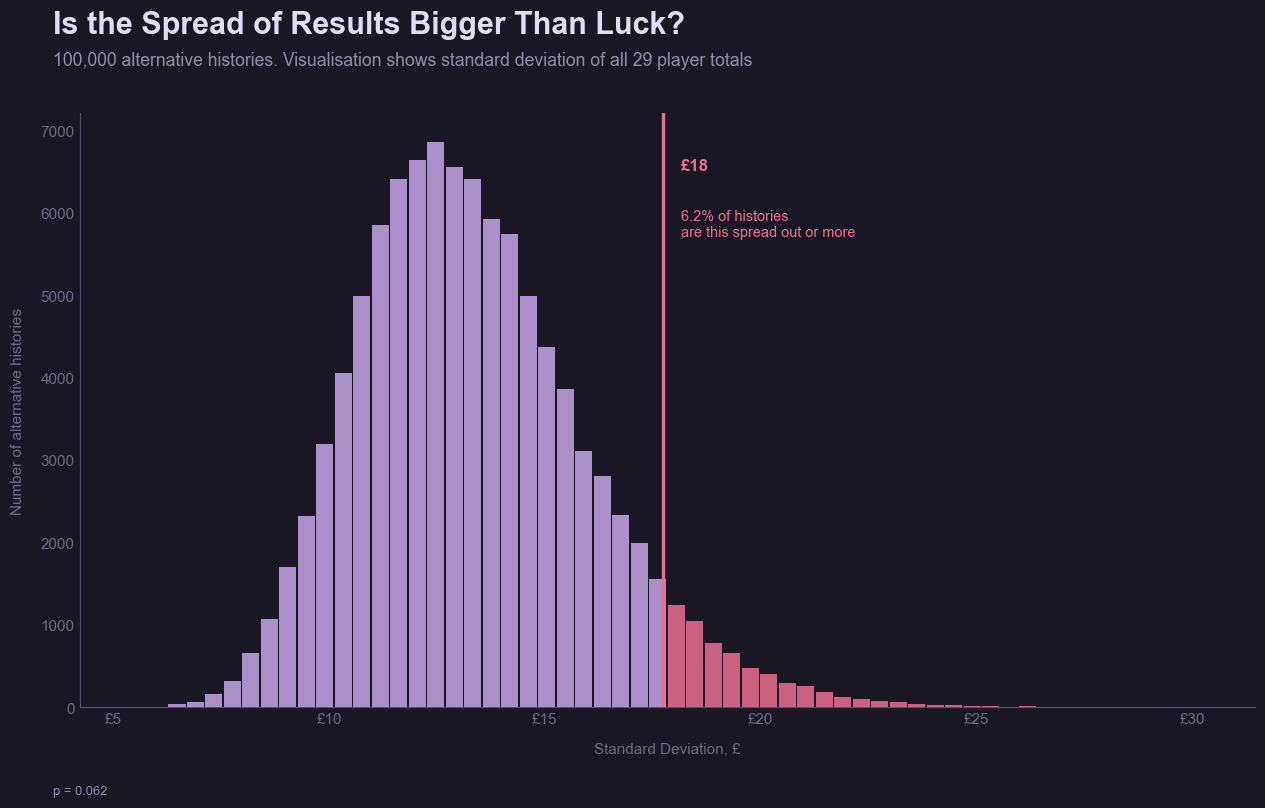

In [7]:
def mc_p(n_extreme, n_sims):
    return (n_extreme + 1) / (n_sims + 1)

spread_obs = totals_obs.std()        
spread_sim = totals_sim.std(axis=1)  

n_extreme = int(np.sum(spread_sim >= spread_obs)) 
p_spread  = mc_p(n_extreme, N_SIMS)
mc_error  = np.sqrt(p_spread * (1 - p_spread) / N_SIMS)
lo, hi    = np.percentile(spread_sim, [5, 95])

print(f"Real spread:                £{spread_obs:.2f}")
print(f"Luck-only spread (average): £{spread_sim.mean():.2f}   (middle 90%: £{lo:.2f} to £{hi:.2f})")
print(f"Histories at least as spread out as reality: {n_extreme:,} of {N_SIMS:,}")
print(f"p = {p_spread:.3f}  (simulation error about ±{mc_error:.3f})")

fig, ax = plt.subplots(figsize=(12, 7.5))

counts, edges = np.histogram(spread_sim, bins=60)
centres = (edges[:-1] + edges[1:]) / 2
width   = edges[1] - edges[0]
ax.bar(centres, counts, width=width * 0.92, zorder=3, alpha=0.85,
       color=np.where(centres >= spread_obs, '#eb6f92', "#c4a7e7")) 

ax.axvline(spread_obs, color='#eb6f92', lw=2.2, zorder=4)

top = counts.max()
ax.text(spread_obs + width, top * 0.97, profit_gbp(spread_obs),
        color='#eb6f92', fontsize=11, fontweight="bold", va="top", ha="left")
ax.text(spread_obs + width, top * 0.88, f"{p_spread:.1%} of histories\nare this spread out or more",
        color='#eb6f92', fontsize=9.5, va="top", ha="left")

ax.xaxis.set_major_formatter(profit_gbp)
ax.set_xlabel("Standard Deviation, £", fontsize=10, labelpad=10)
ax.set_ylabel("Number of alternative histories", fontsize=10, labelpad=10)
ax.grid(False, axis="x")
ax.margins(x=0.03)

fig.subplots_adjust(top=0.84, bottom=0.12, left=0.08, right=0.97)
profit_title_block(fig, ax, "Is the Spread of Results Bigger Than Luck?",
                   f"{N_SIMS:,} alternative histories. Visualisation shows standard deviation of all {n_players} player totals")
footer(fig, f"p = {p_spread:.3f}")
plt.show()

Sachin: 7 games played
Real total:               £77
Luck-only range (95%):    -£29 to £41   (sd £17.96)
Reality beats 100.0% of luck-only histories
As extreme as reality in 6 of 100,000 histories  ->  p < 0.001 (two-sided)


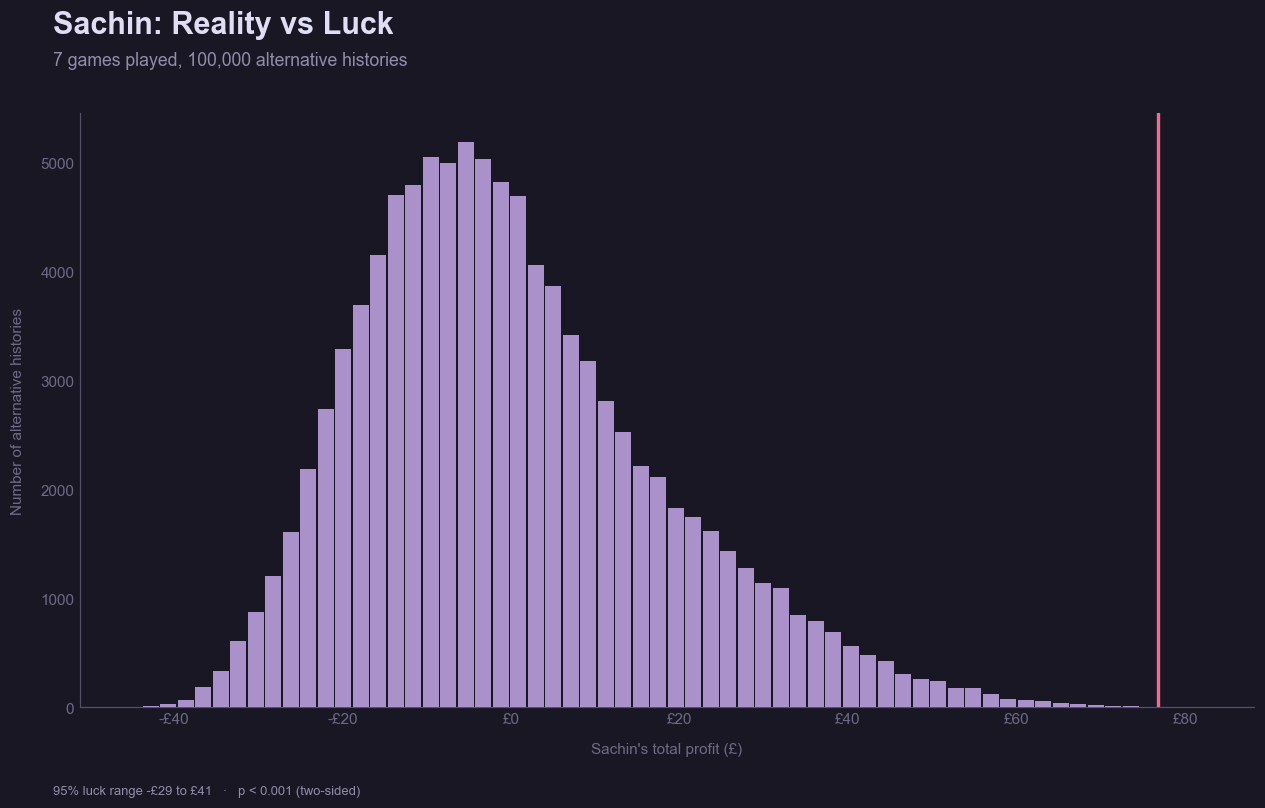

In [9]:
PLAYER = "Sachin"

if PLAYER not in player_list:
    raise ValueError(f"'{PLAYER}' not found. Choose from: {player_list}")

idx       = player_list.index(PLAYER)
real      = totals_obs[idx]                             
luck      = totals_sim[:, idx]                            
n_games   = int((games["player"] == PLAYER).sum())
games_txt = f"{n_games} game" + ("s" if n_games != 1 else "")

lo, hi    = np.percentile(luck, [2.5, 97.5])              
n_extreme = int(np.sum(np.abs(luck) >= abs(real)))      
p_two     = (n_extreme + 1) / (N_SIMS + 1)
p_txt     = "p < 0.001" if p_two < 0.001 else f"p = {p_two:.3f}"
pctile    = ((luck < real).mean() + 0.5 * (luck == real).mean()) * 100 

print(f"{PLAYER}: {games_txt} played")
print(f"Real total:               {profit_gbp(real)}")
print(f"Luck-only range (95%):    {profit_gbp(lo)} to {profit_gbp(hi)}   (sd £{luck.std():.2f})")
print(f"Reality beats {pctile:.1f}% of luck-only histories")
print(f"As extreme as reality in {n_extreme:,} of {N_SIMS:,} histories  ->  {p_txt} (two-sided)")

fig, ax = plt.subplots(figsize=(12, 7.5))

values, freq = np.unique(luck, return_counts=True)
if len(values) <= 40:
    centres, counts = values, freq
    width = np.diff(values).min() if len(values) > 1 else 1.0
else:
    counts, edges = np.histogram(luck, bins=60)
    centres = (edges[:-1] + edges[1:]) / 2
    width   = edges[1] - edges[0]

in_tail = np.abs(centres) >= abs(real) - 1e-9       
ax.bar(centres, counts, width=width * 0.92, zorder=3, alpha=0.85,
       color=np.where(in_tail, "#eb6f92", "#c4a7e7"))

ax.axvline(real, color="#eb6f92", lw=2.2, zorder=4)

ax.xaxis.set_major_formatter(profit_gbp)
ax.set_xlabel(f"{PLAYER}'s total profit (£)", fontsize=10, labelpad=10)
ax.set_ylabel("Number of alternative histories", fontsize=10, labelpad=10)
ax.grid(False, axis="x")
ax.margins(x=0.06)

fig.subplots_adjust(top=0.84, bottom=0.12, left=0.08, right=0.97)
profit_title_block(fig, ax, f"{PLAYER}: Reality vs Luck",
                   f"{games_txt} played, {N_SIMS:,} alternative histories")
footer(fig, f"95% luck range {profit_gbp(lo)} to {profit_gbp(hi)}   ·   {p_txt} (two-sided)")
plt.show()

### Chapter 2. Profit Distribution

Now we are going to model profit distribution within our real dataset, measuring what the most common results are across the board. 

#### 2.1. The Normal Distribution

Since poker is a zero-sum game, the sum of all profits across any session is exactly £0. It follows that we will always have $\mu=0$ across all profits over all sessions. The spread $\sigma$ reflects the variance of outcomes - a higher variance implies a higher "spread" of results.

We assume that individual session profits $X_1, X_2, \ldots, X_n$ are independent and identically distributed draws from some unknown distribution $F$, and presume that:

$$
F \approx \mathcal{N}(0, \sigma^2)
$$

So, $F$ will follow some form of normal distribution over time. $\sigma^2$ is estimated as:

$$
\hat{\sigma}^2 = \frac{1}{n-1} \sum_{i=1}^{n} X_i^2
$$

By the Law of Large Numbers, this estimator converges in probability to the true variance as the number of sessions grows:

$$
\hat{\sigma}^2 \xrightarrow{p} \sigma^2 \quad \text{as } n \to \infty
$$

Meaning the distribution should stabilise around $\mathcal{N}(0, \sigma^2)$ over time, admittedly, maybe slightly longer than I may be alive to play the game. But nonetheless, the graph is a visual test of this hypothesis.

### Formally Defining Density

Let the profits from $n$ session be modelled by our true distribution:

$$
X_1,X_2,\ldots, X_n \overset{\text{iid}}{\sim} F
$$

- Each $X_i \in \mathbb{R}$ represents each players profit/loss per session. 
- $F$ represents the true distribution of results.
- We are making the assumption that each result is independently and identically distributed.

If $F$ is continuous, then there exists a probability density function $f$ such that:

$$
F(x) = \mathbb{P}(X\leq x) = \int_{-\infty}^{x}f(t)~dt
$$

Recall, that a probability density function $f:\mathbb{R}\to\mathbb{R}$ is defined based on the following properties:

$$
f(x)\geq 0~~~\forall x\in\mathbb{R}
$$

and

$$\int_{-\infty}^{\infty}f(x)~dx=1$$

We have that $f(x)$ will return our true density. However, as we do not have the true distribution for our model we must use an estimator to approximate. We define the estimator as follows:

$$
\hat{f}(x) = \frac{1}{nh} \sum_{i=1}^{n} K\left(\frac{x - x_i}{h}\right)
$$

Where $K$ is the kernel function and $h$ is the bandwidth, controlling the smoothness of the curve. Each data point $x_i$ contributes a small Gaussian bump centred on itself.

So, essentially, density on the y-axis exists such that for an interval $[a,b]$ we have:

$$
\mathbb{P}(a<X<b) = \int_{a}^{b}\hat{f}(x)~dx
$$
and
$$
\int_{-\infty}^{\infty}\hat{f}(x)~dx=1
$$

### Interpreting Density

The y-axis represents probability density, rather than probability itself. It describes how concentrated the probability of a session's profit or loss is around a particular value on the x-axis.

A higher density at a given profit level indicates that results are more concentrated around that value. Conversely, a lower density indicates that results are less concentrated around it.

Importantly, density is not the probability of achieving an exact profit. For a continuous distribution, the probability of observing any one exact value is zero. Instead, probabilities are obtained by calculating the area under the density curve over an interval.

For example, the probability that a session results in a profit between £0 and £50 is given by:

$$
\mathbb{P}(0 < X < 50) = \int_0^{50} \hat{f}(x)\,dx
$$

The total area under the estimated density curve is equal to 1, representing the entire probability distribution:

$$
\int_{-\infty}^{\infty}\hat{f}(x)\,dx=1
$$

Therefore, the y-axis should be interpreted as a measure of how probability is distributed across different possible session outcomes, rather than as a direct measure of the likelihood of any individual result.

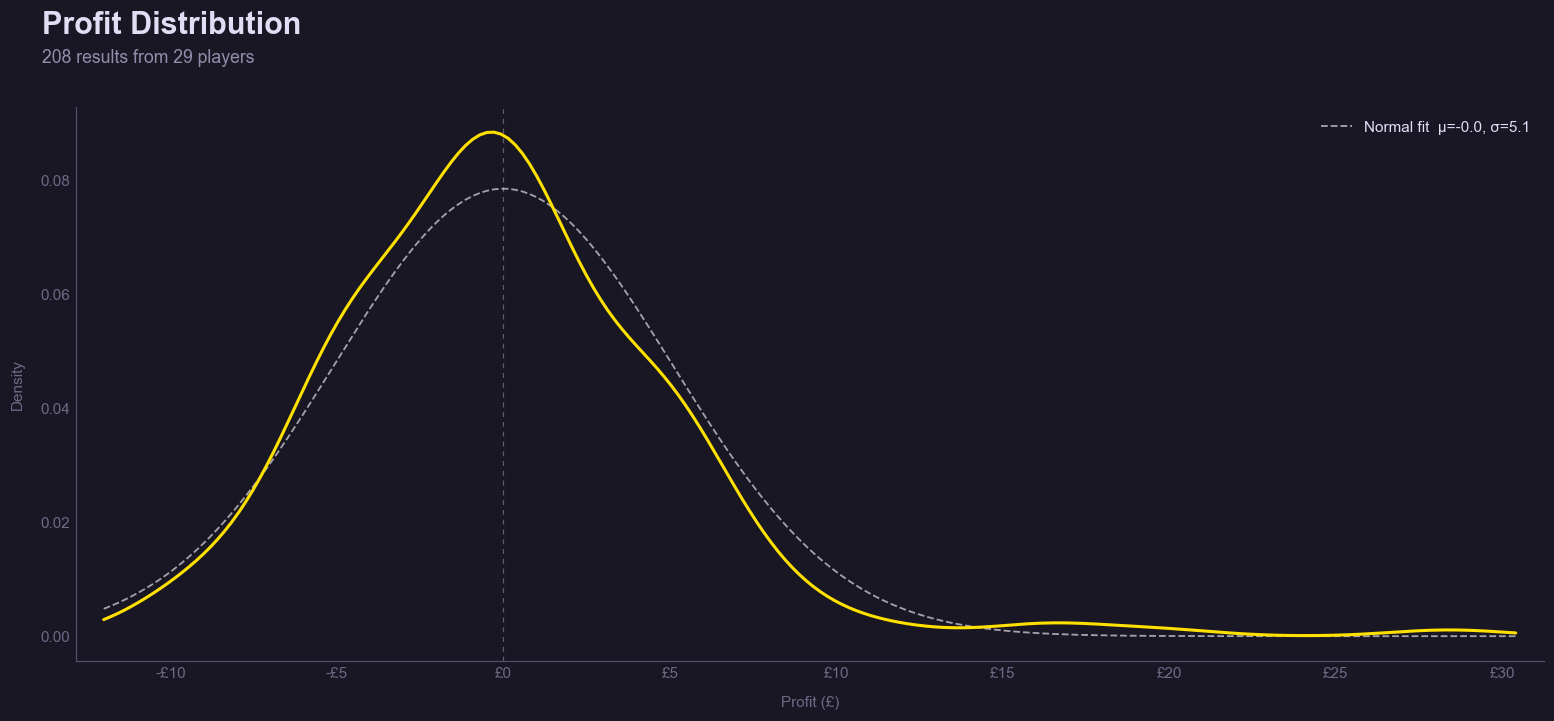

In [10]:
all_profits = games["profit"]
mu, std = norm.fit(all_profits)
kde = stats.gaussian_kde(all_profits)
kde_x = np.linspace(all_profits.min() - 2, all_profits.max() + 2, 200)

fig, ax = plt.subplots(figsize=(15, 7))

ax.plot(kde_x, kde(kde_x), color="#FFE100", lw=2, solid_capstyle="round", zorder=3)
ax.plot(kde_x, norm.pdf(kde_x, mu, std), color="white", lw=1.2, ls="--", alpha=0.6,
        label=f"Normal fit  μ={mu:.1f}, σ={std:.1f}", zorder=2)
ax.axvline(0, color=MUTED, lw=0.8, ls=(0, (4, 4)), alpha=0.6, zorder=1)

ax.xaxis.set_major_formatter(profit_gbp)
ax.set_xlabel("Profit (£)", fontsize=10, labelpad=10)
ax.set_ylabel("Density", fontsize=10, labelpad=10)
ax.grid(False)
ax.margins(x=0.02)
ax.legend(frameon=False, loc="upper right")

fig.subplots_adjust(top=0.84, bottom=0.12, left=0.08, right=0.97)
profit_title_block(fig, ax, "Profit Distribution",
                   f"{len(all_profits)} results from {games['player'].nunique()} players")
profit_footer(fig)
plt.show()

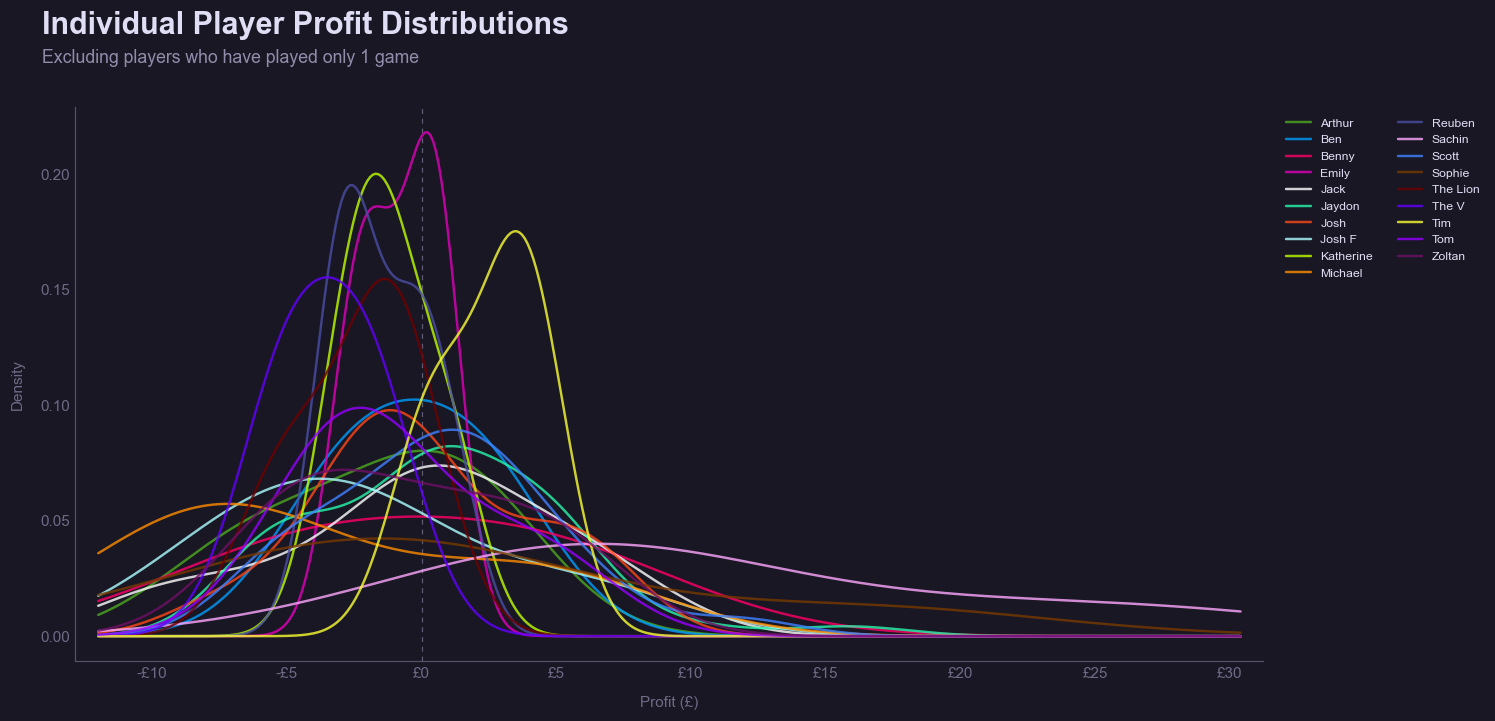

In [11]:
profits = games["profit"]
kde_x = np.linspace(profits.min() - 2, profits.max() + 2, 400)

fig, ax = plt.subplots(figsize=(15, 7))

for player, player_profits in games.groupby("player")["profit"]:
    if player_profits.nunique() < 2:
        continue
    ax.plot(kde_x, stats.gaussian_kde(player_profits)(kde_x), color=player_colours.get(player, "#888888"),
            lw=1.6, alpha=0.8, label=player, solid_capstyle="round")

ax.axvline(0, color=MUTED, lw=0.8, ls=(0, (4, 4)), alpha=0.6, zorder=1)

ax.xaxis.set_major_formatter(profit_gbp)
ax.set_xlabel("Profit (£)", fontsize=10, labelpad=10)
ax.set_ylabel("Density", fontsize=10, labelpad=10)
ax.grid(False)
ax.margins(x=0.02)
ax.legend(fontsize=8, ncol=2, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0))

fig.subplots_adjust(top=0.84, bottom=0.12, left=0.08, right=0.80)
profit_title_block(fig, ax, "Individual Player Profit Distributions",
                   "Excluding players who have played only 1 game")
profit_footer(fig)
plt.show()

How well is the pot distributed at the end of each match? What better way to model this than using candles, similar to that of a stock. 

Each candle represents one game. Unfortunately, 'games' do not have closing prices, opening prices and so on. So, we need to find another way to define our candles. 

- The wick represents the difference between the largest win and the largest loss.
- The body represents the middle 50% of players
- The white tick is the median.
- A candle is green if its median is higher than that of the previous candle.
- A candle is red if its median is lower than that of the previous candle.
- A candle is faded if the game contained fewer than 4 players.

Our volume indicator underneath the graph just represents the size of the pot in each game. 

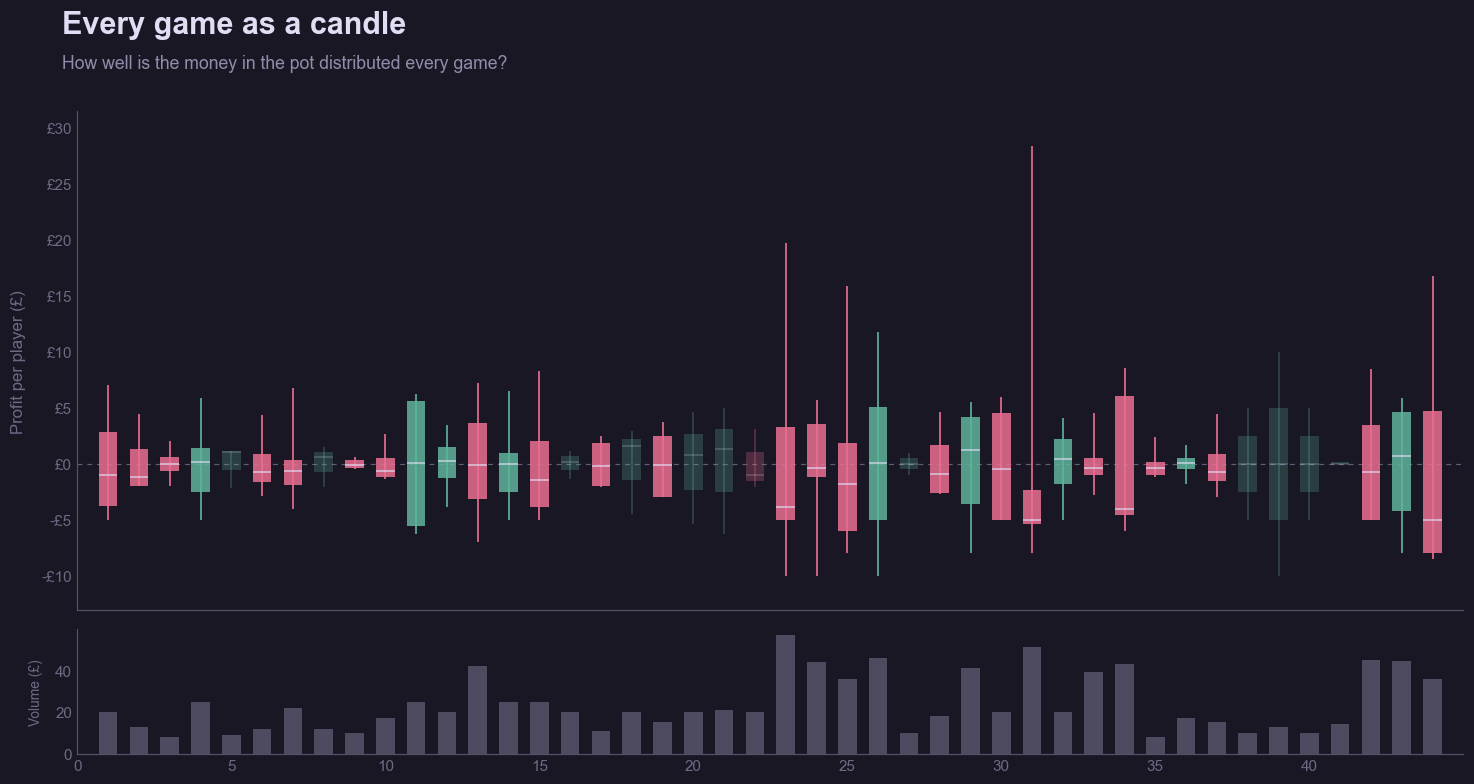

In [13]:
MIN_PLAYERS = 4

candles = games.groupby("game_id").agg(
    low=("profit", "min"),
    high=("profit", "max"),
    q1=("profit", lambda s: s.quantile(0.25)),
    q3=("profit", lambda s: s.quantile(0.75)),
    median=("profit", "median"),
    pot=("buy_in", "sum"),
    n=("player", "count"),
).reset_index()

colours = np.where(candles["median"] >= 0, "#5fb49c", "#eb6f92")
fade = np.where(candles["n"] >= MIN_PLAYERS, 1.0, 0.3)
x = candles["game_id"].to_numpy()
body_width = 0.6
min_body = (candles["high"].max() - candles["low"].min()) * 0.004

fig = plt.figure(figsize=(14, 8))
gs = gridspec.GridSpec(2, 1, height_ratios=[4, 1], hspace=0.06)
ax = fig.add_subplot(gs[0])
axv = fig.add_subplot(gs[1], sharex=ax)

ax.vlines(x, candles["low"], candles["high"], colors=[to_rgba(c, a) for c, a in zip(colours, fade)], lw=1.1, zorder=2)
ax.bar(x, np.maximum(candles["q3"] - candles["q1"], min_body), bottom=candles["q1"], width=body_width,
       color=[to_rgba(c, 0.85 * a) for c, a in zip(colours, fade)], edgecolor="none", zorder=3)
ax.hlines(candles["median"], x - body_width / 2, x + body_width / 2,
          colors=[to_rgba(FG, 0.8 * a) for a in fade], lw=1.0, zorder=4)
ax.axhline(0, color=MUTED, lw=0.8, ls=(0, (4, 4)), alpha=0.6)

axv.bar(x, candles["pot"], width=body_width, color=MUTED, alpha=0.45, edgecolor="none")
axv.grid(False)
axv.set_ylabel("Volume (£)", fontsize=9, labelpad=8)

ax.set_ylabel("Profit per player (£)", fontsize=11, labelpad=10)
ax.yaxis.set_major_formatter(profit_gbp)
ax.margins(y=0.08)
ax.set_xlim(x.min() - 1, x.max() + 1)
plt.setp(ax.get_xticklabels(), visible=False)
axv.set_xticks(range(0, x.max() + 1, 5))

fig.subplots_adjust(top=0.85, bottom=0.12, left=0.07, right=0.97)
title_block(fig, ax, "Every game as a candle", "How well is the money in the pot distributed every game?")
footer(fig)
plt.show()

### Chapter 3. Overall Rating System (OVR)

The objective of the OVR system is to create a rating that reflects a player's ability, primarily based on how they finish per game compare and the strength of their opponents.

Profit alone is not a reliable measure of poker ability, as it can be heavily influenced by luck, risk-taking and the number of games played. Instead, OVR will measure how well a player performs relative to the other players at their table, taking into account their existing ratings.

The system will reward players for winning and penalise players for losing. However, the magnitude of these adjustments will depend on the strength of their opposition and whether they performed above or below expectations.

#### The Formula

The OVR adjustment is calculated using two separate components:

1. Result points: A reward or penalty based on the player's actual finishing position.
2. Expectation points: An additional reward or penalty based on how their actual finishing position compares to their expected position.

The final rating adjustment is calculated as:

$$
\Delta OVR = R + E
$$

With, 

$$
R = B\left(\frac{n+1-2p}{n-1}\right)~~,~~E = K(e-p)
$$

Where, 
- $B$ = Base rating adjustment. (Some scalar to be chosen)
- $K$ = Expectation adjustment factor. (Some scalar to be chosen)
- $n$ = Number of players in the game.
- $p$ = Actual finishing position.
- $e$ = Expected finishing position.

Combining the two components gives our final formula:

$$
\Delta OVR =
B\left(\frac{n+1-2p}{n-1}\right)
+K(e-p)
$$

The player's new OVR is then calculated as follows:

$$
OVR_{\text{new}}=OVR_{\text{old}}+\Delta OVR
$$

In [14]:
BASE = 10
EXPECTATION = 5
STARTING_OVR = 40
MIN_GAMES = 5


def calculate_ovr_history(data):
    ratings = {player: STARTING_OVR for player in data["player"].unique()}
    rows = []
    for game_id, game in data.sort_values("game_id", kind="stable").groupby("game_id"):
        n = len(game)
        if n < 2:
            continue
        before = game["player"].map(ratings)
        expected = before.rank(ascending=False)
        actual = game["profit"].rank(ascending=False)
        change = BASE * ((n + 1 - 2 * actual) / (n - 1)) + EXPECTATION * (expected - actual)
        after = (before + change).clip(lower=1)
        ratings.update(zip(game["player"], after))
        rows.append(pd.DataFrame({"game_id": game_id, "player": game["player"].values,
                                  "profit": game["profit"].values, "ovr_change": change.values,
                                  "ovr": after.values}))
    return pd.concat(rows, ignore_index=True)


game_counts = games.groupby("player")["game_id"].nunique()
is_low = games["player"].isin(game_counts[game_counts <= MIN_GAMES].index)
pooled = pd.concat([
    games.loc[~is_low, ["game_id", "player", "profit"]],
    games[is_low].groupby("game_id", as_index=False).agg(profit=("profit", "mean")).assign(player="<5G"),
], ignore_index=True)

df_ovr_individual = calculate_ovr_history(games[["game_id", "player", "profit"]])
df_ovr_history = calculate_ovr_history(pooled)

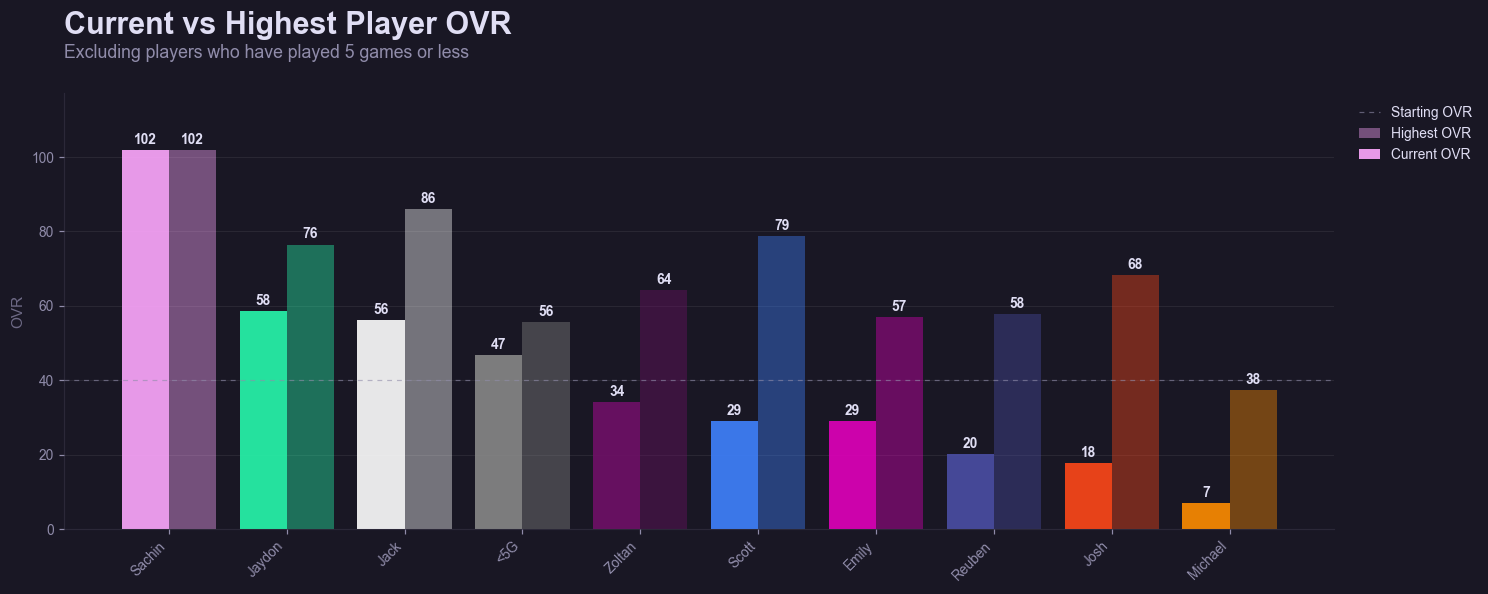

In [15]:
latest = df_ovr_history.sort_values("game_id", kind="stable").groupby("player")["ovr"]
current_ovr = latest.last().sort_values(ascending=False)
best_ovr = latest.max()[current_ovr.index]

players = current_ovr.index.tolist()
x = np.arange(len(players))
width = 0.4
colours = [player_colours.get(p, "#888888") for p in players]

fig, ax = plt.subplots(figsize=(15, 6))

best_bars = ax.bar(x + width / 2, best_ovr, width=width, color=colours, label="Highest OVR", edgecolor="none", alpha=0.4)
current_bars = ax.bar(x - width / 2, current_ovr, width=width, color=colours, label="Current OVR", edgecolor="none", alpha=0.9)
for bars in (current_bars, best_bars):
    ax.bar_label(bars, fmt="%.0f", padding=2, fontsize=9, fontweight="bold", color=FG)

soften_axes(ax, ref_y=STARTING_OVR, ref_label="Starting OVR")
soften_legend(ax)

title_block(fig, ax, "Current vs Highest Player OVR", "Excluding players who have played 5 games or less")

ax.set_ylabel("OVR")
ax.set_xticks(x, players, rotation=45, ha="right")
ax.set_ylim(0, max(best_ovr.max(), STARTING_OVR) * 1.15)

fig.subplots_adjust(left=0.06, right=0.83, top=0.84, bottom=0.18)
plt.show()

How well does our system of rating skill relate to tangible success within the game? 

The scatter plot places each player as a single point: their current OVR on the x-axis, their total profit across all sessions on the y-axis. The regression line is a straight line of best fit drawn through those points.

Pearson's coefficient, $r$, summarises how tightly the points cluster around the line. We have that $-1\leq r\leq 1$. Formally, we define $r$ as follows:

$$
r = \frac{\text{Cov}(O,P)}{\sigma_O~\sigma_P}
$$

Note, $\text{Cov}(O,P)$ is defined as the covariance between O, Current OVR, and P, total profit. We also have that $\sigma_O$,$\sigma_P$ represents the standard deviation of the current OVR and total profit respectively.

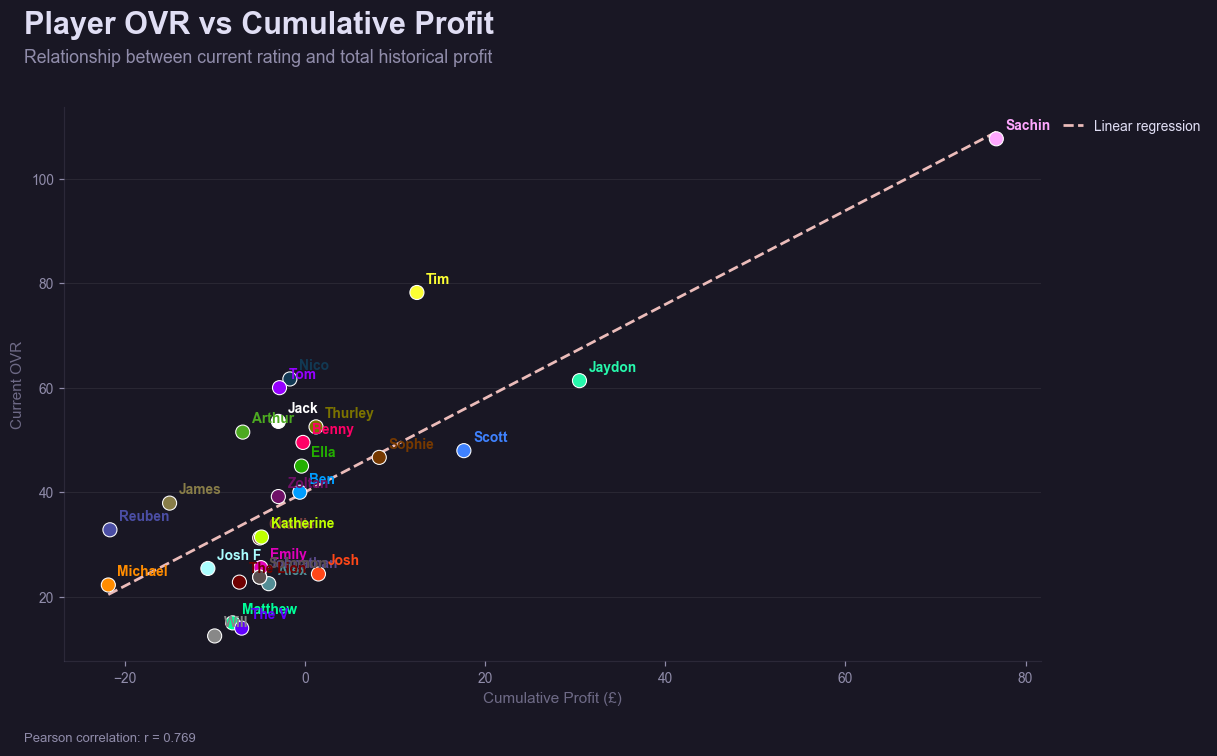

In [16]:
corr = pd.DataFrame({
    "ovr": df_ovr_individual.sort_values("game_id", kind="stable").groupby("player")["ovr"].last(),
    "profit": games.groupby("player")["profit"].sum(),
}).dropna()

slope, intercept, r, *_ = stats.linregress(corr["profit"], corr["ovr"])
x_line = np.array([corr["profit"].min(), corr["profit"].max()])
colours = [player_colours.get(p, "#888888") for p in corr.index]

fig, ax = plt.subplots(figsize=(12, 7))

ax.scatter(corr["profit"], corr["ovr"], c=colours, s=85, edgecolor="white", linewidth=0.7, zorder=3)
for player, colour in zip(corr.index, colours):
    ax.annotate(player, (corr.at[player, "profit"], corr.at[player, "ovr"]), xytext=(6, 6),
                textcoords="offset points", color=colour, fontsize=9, fontweight="bold")
ax.plot(x_line, intercept + slope * x_line, color="#ebbcba", lw=1.8, ls="--", label="Linear regression")

soften_axes(ax)
soften_legend(ax)

title_block(fig, ax, "Player OVR vs Cumulative Profit", "Relationship between current rating and total historical profit")
ax.set_xlabel("Cumulative Profit (£)")
ax.set_ylabel("Current OVR")
footer(fig, f"Pearson correlation: r = {r:.3f}")

fig.subplots_adjust(left=0.09, right=0.83, top=0.84, bottom=0.12)
plt.show()

In [17]:
def align_axes(ax_left, ax_right, left_ref, right_ref=0, pad=0.10, f_min=0.08, f_max=0.92):
    def extents(ax, ref):
        lo, hi = ax.dataLim.y0, ax.dataLim.y1
        return max(ref - lo, 0), max(hi - ref, 0)

    below_l, above_l = extents(ax_left, left_ref)
    below_r, above_r = extents(ax_right, right_ref)

    f = max(below_l / ((below_l + above_l) or 1),
            below_r / ((below_r + above_r) or 1))
    f = min(max(f, f_min), f_max)

    for ax, ref, below, above in [(ax_left, left_ref, below_l, above_l),
                                  (ax_right, right_ref, below_r, above_r)]:
        span = max(below / f, above / (1 - f)) * (1 + pad)
        ax.set_ylim(ref - f * span, ref + (1 - f) * span)

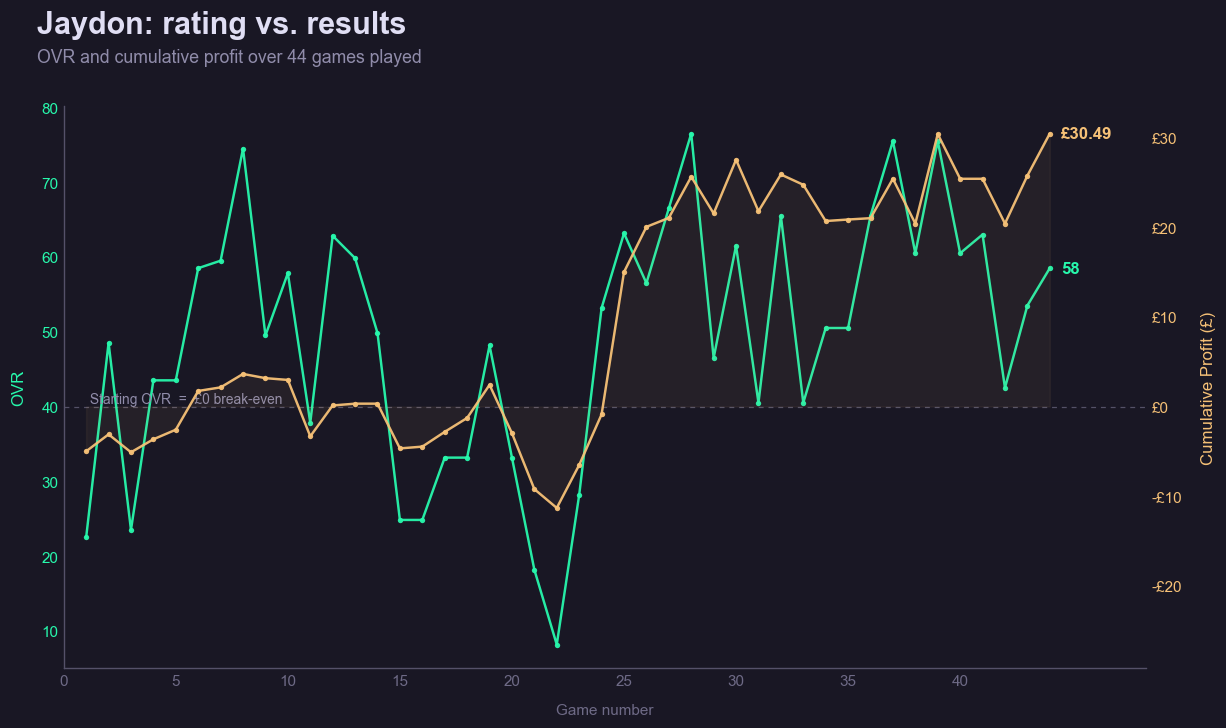

In [18]:
PLAYER = "Jaydon"

if PLAYER not in df_ovr_history["player"].values:
    raise ValueError(f"'{PLAYER}' not found. Choose from: {sorted(df_ovr_history['player'].unique())}")

history = df_ovr_history[df_ovr_history["player"] == PLAYER].sort_values("game_id").copy()
history["cumulative_profit"] = history["profit"].cumsum()

colour_ovr = player_colours.get(PLAYER, "#c4a7e7")
colour_profit = "#f6c177"
line_kw = dict(lw=1.6, alpha=0.95, marker="o", ms=3.5, mew=0, solid_capstyle="round", zorder=3)

fig, ax1 = plt.subplots(figsize=(12, 7))
ax2 = ax1.twinx()

ax1.plot(history["game_id"], history["ovr"], color=colour_ovr, **line_kw)
ax1.axhline(STARTING_OVR, color=MUTED, lw=0.8, ls=(0, (4, 4)), alpha=0.5)
ax1.text(history["game_id"].min(), STARTING_OVR, " Starting OVR  =  £0 break-even", color=MUTED, fontsize=9, va="bottom")

ax2.plot(history["game_id"], history["cumulative_profit"], color=colour_profit, **line_kw)
ax2.fill_between(history["game_id"], 0, history["cumulative_profit"], color=colour_profit, alpha=0.06, zorder=1)

ax1.set_ylabel("OVR", color=colour_ovr, fontsize=11, labelpad=10)
ax2.set_ylabel("Cumulative Profit (£)", color=colour_profit, fontsize=11, labelpad=12)
ax1.tick_params(axis="y", colors=colour_ovr)
ax2.tick_params(axis="y", colors=colour_profit)
ax2.grid(False)
ax2.yaxis.set_major_formatter(profit_gbp)
ax1.set_xlabel("Game number", fontsize=10, labelpad=10)
ax1.set_xticks(range(0, games["game_id"].max() + 1, 5))

align_axes(ax1, ax2, left_ref=STARTING_OVR, right_ref=0)

x_min, x_max = history["game_id"].min(), history["game_id"].max()
x_pad = max(3, (x_max - x_min) * 0.10)
ax1.set_xlim(x_min - 1, x_max + x_pad)

last = history.iloc[-1]


def axes_frac(ax, y):
    lo, hi = ax.get_ylim()
    return (y - lo) / (hi - lo)


f_ovr = axes_frac(ax1, last["ovr"])
f_profit = axes_frac(ax2, last["cumulative_profit"])

gap = 0.06
if abs(f_ovr - f_profit) < gap:
    mid = (f_ovr + f_profit) / 2
    f_ovr, f_profit = (mid + gap / 2, mid - gap / 2) if f_ovr >= f_profit else (mid - gap / 2, mid + gap / 2)

tag_x = x_max + x_pad * 0.12
tag_kw = dict(xycoords=ax1.get_xaxis_transform(), fontsize=11, fontweight="bold", va="center", ha="left",
              bbox=dict(boxstyle="round,pad=0.25", fc=BG, ec="none", alpha=0.85))
ax1.annotate(f"{last['ovr']:.0f}", xy=(tag_x, f_ovr), color=colour_ovr, **tag_kw)
ax1.annotate(f"£{last['cumulative_profit']:.2f}", xy=(tag_x, f_profit), color=colour_profit, **tag_kw)

fig.subplots_adjust(top=0.84, bottom=0.11, left=0.08, right=0.90)
title_block(fig, ax1, f"{PLAYER}: rating vs. results", f"OVR and cumulative profit over {len(history)} games played")
footer(fig)
plt.show()